<a href="https://colab.research.google.com/github/qtrong0205/plant-care-ai-service/blob/main/classification/training/train_plant_disease_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Plant Care - Classification

In [1]:
from pathlib import Path

%cd /content
if not Path("/content/plant-care-ai-service").exists():
    !git clone https://github.com/qtrong0205/plant-care-ai-service.git
else:
    %cd /content/plant-care-ai-service
    !git pull
%cd /content/plant-care-ai-service/classification/training

/content
Cloning into 'plant-care-ai-service'...
remote: Enumerating objects: 83, done.
remote: Counting objects: 100% (83/83), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 83 (delta 21), reused 66 (delta 16), pack-reused 0 (from 0)
Receiving objects: 100% (83/83), 2.55 MiB | 5.38 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/plant-care-ai-service/classification/training


## 1. Problem Definition

- 1.1. Objective

  The objective of this project is to build a deep learning model that automatically classifies plant diseases from leaf images. The trained model will be deployed as an **ONNX model** in a FastAPI service to provide real-time disease diagnosis for the Plant Care Assistant application.

- 1.2. Dataset

  The model is trained on the **PlantVillage** dataset, which contains approximately 54,000 images across 38 classes covering 14 plant species and their disease categories. To accelerate experimentation and hyperparameter tuning, the initial training will use only 20% of the training dataset (approximately 10,000 images). After selecting the best configuration, the final model will be trained on the full dataset.

- 1.3. Evaluation Metrics

  Model performance will be evaluated using Accuracy, Precision, Recall, F1-score, and the Confusion Matrix.

## 2. Import libraries and Setup device agnostic code

In [2]:
import os
import torch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path
from torch import nn
from tqdm.auto import tqdm

In [3]:
# Device agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## 3. Load & Explore Data



### 3.1. Download and unzip data

In [4]:
from pathlib import Path

DATA_DIR = Path("data/plantvillage dataset/color")

if DATA_DIR.exists() and any(DATA_DIR.iterdir()):
    print(f"Dataset already exist at '{DATA_DIR}', download skipped.")
else:
    print("Downloading data from Kaggle...")
    !kaggle datasets download -d abdallahalidev/plantvillage-dataset
    !unzip -q plantvillage-dataset.zip -d data/
    print("Downloaded and unziped.")

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:09<00:00, 243MB/s]

Downloaded and unziped.


In [5]:
from split_dataset import split_dataset

SPLIT_PATH = Path("data/split")
train_path = Path("data/split/train")
test_path = Path("data/split/test")

if train_path.exists() and test_path.exists() and len(list(train_path.iterdir())) == 38:
    print("Already splitted")
else:
    split_dataset(
        source_dir="data/plantvillage dataset/color",
        output_dir=SPLIT_PATH,
        train_ratio=0.8,
    )

Dataset successfully split into 'data/split'.


### 3.2. Create a Custom `ImageDataset` Class

In this section, we implement a custom `ImageDataset` class that accepts the dataset directory, image transformations, and a subset ratio. The `subset_ratio` parameter allows loading only a specified percentage of the original dataset, enabling faster experimentation and model training.

The implementation of the `ImageDataset` class is available in the project repository:

> **GitHub:** https://github.com/qtrong0205/plant-care-ai-service/blob/main/classification/training/data_setup.py

In [6]:
from data_setup import ImageDataset

# Create a dataset with custom ImageDataset
train_dataset = ImageDataset(
    targ_dir=train_path,
    transform=None,
    subset_ratio=0.2,
    seed=42,
)
test_dataset = ImageDataset(
    targ_dir=test_path,
    transform=None,
    subset_ratio=0.2,
    seed=42,
)

print(f"Number of classes in train dataset: {len(train_dataset.classes)}")
print(f"Number of images in train dataset: {len(train_dataset)}")
print(f"Number of classes in test dataset: {len(test_dataset.classes)}")
print(f"Number of images in test dataset: {len(test_dataset)}")

Number of classes in train dataset: 38
Number of images in train dataset: 8673
Number of classes in test dataset: 38
Number of images in test dataset: 2165


In [7]:
from data_setup import find_classes

class_names, class_to_idx = find_classes(train_path)
class_names

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

### 3.3. Visualize an image

Random image path: data/split/train/Corn_(maize)___healthy/333922bd-09d6-4039-9975-894d77fec8eb___R.S_HL 5496 copy.jpg
Image class: Corn_(maize)___healthy
Image height: 256
Image width: 256


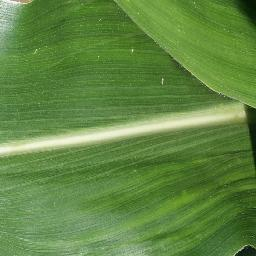

In [8]:
import random
from PIL import Image

# Set seed
# random.seed(42)

# 1. Get all image paths (* means "any combination")
image_path_list = list(SPLIT_PATH.glob("*/*/*.jpg"))

# 2. Get random image path
random_image_path = random.choice(image_path_list)

# 3. Get image class from path name (the image class is the name of the directory where the image is stored)
image_class = random_image_path.parent.stem

# 4. Open image
img = Image.open(random_image_path)

# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img

(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

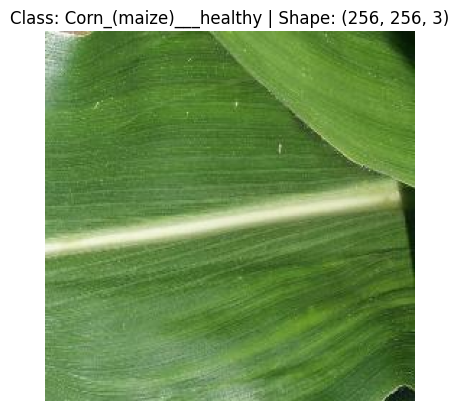

In [9]:
# Turn image into numpy array
img_as_array = np.asarray(img)

plt.imshow(img_as_array)
plt.title(f"Class: {image_class} | Shape: {img_as_array.shape}")
plt.axis(False)

### 3.4. Create DataLoaders

In this section, we recreate the training and testing datasets by applying the appropriate image transformations. We then create `DataLoader` objects for each dataset to enable efficient batch loading, shuffling, and data iteration during model training and evaluation.

In [10]:
import os
from data_setup import create_transform
from data_setup import create_dataloader

NUM_WORKERS = os.cpu_count()
BATCH_SIZE = 32

# Create train and test transform
train_transform = create_transform(size=(224, 224), train=True)
test_transform = create_transform(size=(224, 224), train=False)

# Create train and test dataset
train_dataset = ImageDataset(targ_dir=train_path, transform=train_transform, subset_ratio=0.2, seed=42)
test_dataset = ImageDataset(targ_dir=test_path, transform=test_transform, subset_ratio=0.2, seed=42)

# Create train and test dataloader
train_dataloader = create_dataloader(dataset=train_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=True)
test_dataloader = create_dataloader(dataset=test_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, shuffle=False)

### 3.5. Plot Random Images from the DataLoader

To verify that the preprocessing pipeline is applied correctly, we randomly sample a few images from the `DataLoader`, reverse the normalization for visualization, and display their corresponding class labels.

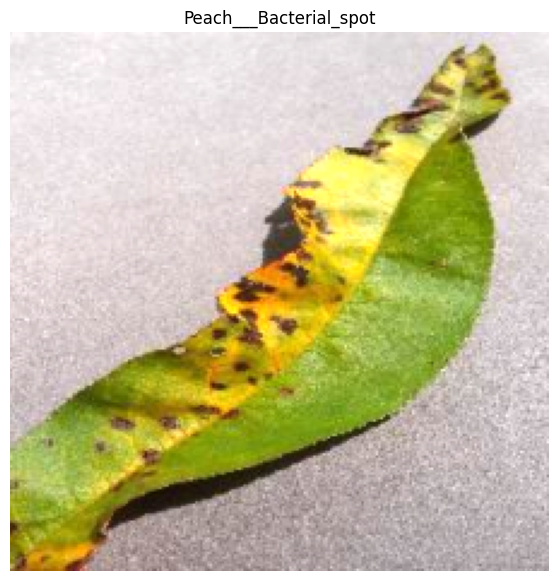

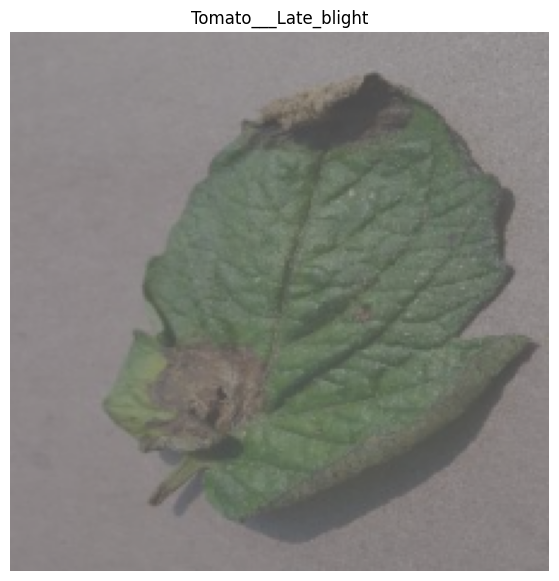

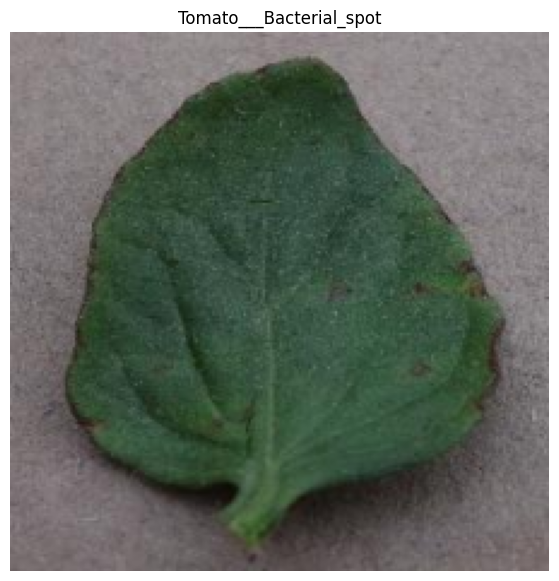

In [11]:
from utils import plot_transformed_images

plot_transformed_images(dataloader=train_dataloader, class_names=class_names, n=3, seed=42)

## 4. Model Training

In this section, we initialize a pretrained MobileNetV2 model, configure it for the plant disease classification task, and train it on the prepared dataset using transfer learning.

### 4.1. Build the Model

To improve code modularity and reusability, the model initialization is encapsulated in a helper function. This function loads a pretrained MobileNetV2 model, freezes the feature extraction layers, replaces the classifier to match the target number of classes, and optionally moves the model to the specified device.

The complete implementation is available in the project repository:

- **Source code:** https://github.com/qtrong0205/plant-care-ai-service/blob/main/classification/training/model_builder.py

In [12]:
from model_builder import build_model

model = build_model(num_classes=38, device=device)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 97.3MB/s]


### 4.2. Use `torchinfo` to get an idea of the shapes going through model

In [13]:
# Install torchinfo if it's not available, import it if it is
try:
    import torchinfo
except:
    !pip install torchinfo
    import torchinfo

from torchinfo import summary
summary(model, input_size=[32, 3, 224, 224]) # do a test pass through of an example input size

Layer (type:depth-idx)                             Output Shape              Param #
MobileNetV2                                        [32, 38]                  --
├─Sequential: 1-1                                  [32, 1280, 7, 7]          --
│    └─Conv2dNormActivation: 2-1                   [32, 32, 112, 112]        --
│    │    └─Conv2d: 3-1                            [32, 32, 112, 112]        (864)
│    │    └─BatchNorm2d: 3-2                       [32, 32, 112, 112]        (64)
│    │    └─ReLU6: 3-3                             [32, 32, 112, 112]        --
│    └─InvertedResidual: 2-2                       [32, 16, 112, 112]        --
│    │    └─Sequential: 3-4                        [32, 16, 112, 112]        (896)
│    └─InvertedResidual: 2-3                       [32, 24, 56, 56]          --
│    │    └─Sequential: 3-5                        [32, 24, 56, 56]          (5,136)
│    └─InvertedResidual: 2-4                       [32, 24, 56, 56]          --
│    │    └─Sequential

### 4.3. Configure the Training Pipeline

We define the loss function, optimizer, and other training configurations required for model optimization.

In [14]:
# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model.classifier.parameters(), lr=0.01, momentum=0.9)

### 4.4. Model Utilities

To keep the notebook concise and maintainable, the model construction and training utilities are implemented as reusable helper functions. These utilities include loading the pretrained MobileNetV2 model, configuring the classifier, and other functions used throughout the training pipeline.

The complete implementation can be found in the project repository:

- **Source code:** https://github.com/qtrong0205/plant-care-ai-service/blob/main/classification/training/engine.py

In [15]:
from engine import train

NUM_EPOCHS = 5
model_results = train(model=model,
                      train_dataloader=train_dataloader,
                      test_dataloader=test_dataloader,
                      loss_fn=loss_fn,
                      optimizer=optimizer,
                      epochs=NUM_EPOCHS,
                      device=device)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.1680 | train_acc: 0.6895 | test_loss: 0.4202 | test_acc: 0.8713
  → New best model saved (test_acc=0.8713)
Epoch: 2 | train_loss: 0.6331 | train_acc: 0.8232 | test_loss: 0.2455 | test_acc: 0.9232
  → New best model saved (test_acc=0.9232)
Epoch: 3 | train_loss: 0.5609 | train_acc: 0.8400 | test_loss: 0.2345 | test_acc: 0.9322
  → New best model saved (test_acc=0.9322)
Epoch: 4 | train_loss: 0.4738 | train_acc: 0.8597 | test_loss: 0.1942 | test_acc: 0.9419
  → New best model saved (test_acc=0.9419)
Epoch: 5 | train_loss: 0.4505 | train_acc: 0.8670 | test_loss: 0.2046 | test_acc: 0.9290


In [16]:
model_results

{'train_loss': [1.1680367822375368,
  0.6331000253558159,
  0.5608626477803815,
  0.47380448439541983,
  0.4504543128149474],
 'train_acc': [0.689453125,
  0.8231847426470589,
  0.8399586397058824,
  0.8597196691176471,
  0.8669577205882353],
 'test_loss': [0.4202159165185602,
  0.24547629967770157,
  0.23454114954973407,
  0.19419835203477895,
  0.2045683373358128],
 'test_acc': [0.8713016456582633,
  0.9232317927170869,
  0.9321822478991596,
  0.9418548669467787,
  0.9289872198879552]}

### 4.5. Visualize Training Results

Plotting the training loss and evaluation metrics to analyze the model's learning progress and overall performance.

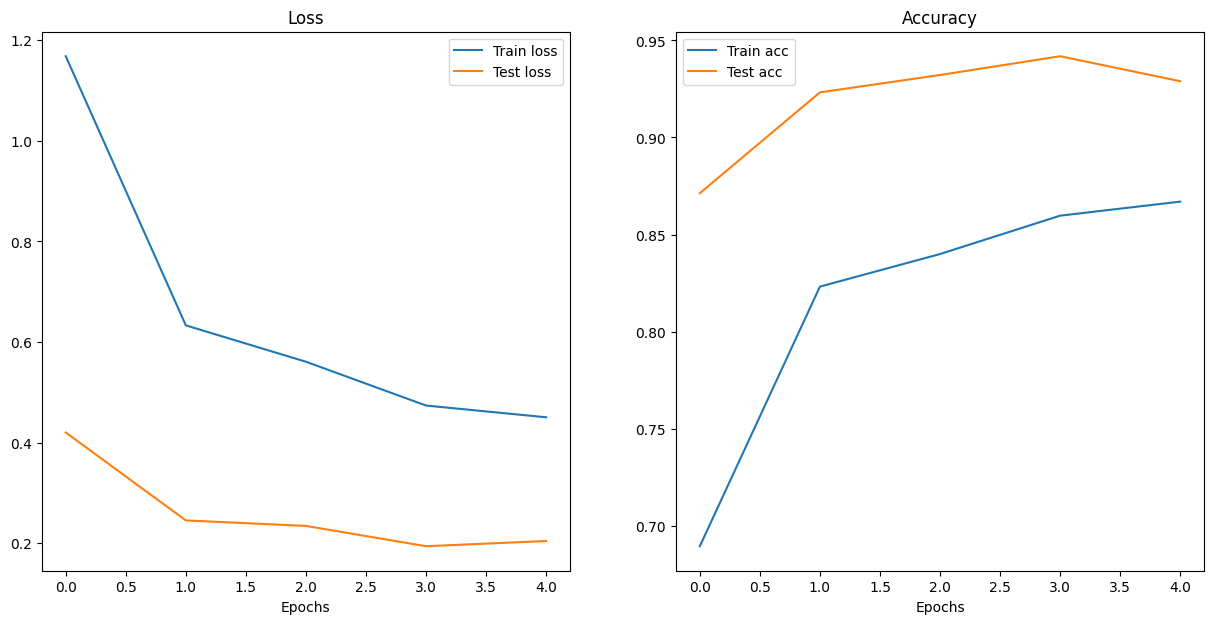

In [17]:
from utils import plot_loss_curves

plot_loss_curves(model_results)